# 04 – Research Question 2: Predicting Pollutant Concentrations with Linear Regression

**Project:** Analyzing Air Quality Patterns Across Texas (CSE 4334 Data Mining)

### Research Question 2
**Can we use historical air quality data to predict pollutant concentrations?**

### Methods: only what was covered in class
This notebook uses only the methods from the two lecture decks, **Lecture 06 – Linear Regression** (LR) and **Variable Selection** (VS). Each step names the slide it comes from:

| Step | Method | Slides |
|---|---|---|
| Exploratory data analysis | histograms, correlation matrix / heatmap | LR 31–33, 84, 97–99; VS 18 |
| Simple linear regression | OLS with one predictor | LR 19–22, 34–35 |
| Multiple linear regression | OLS, coefficient interpretation, marginal vs. conditional | LR 23–29, 36–40 |
| Inference | t-tests, confidence intervals, overall F-test, R², adjusted R² | LR 42–48, 82–83 |
| Categorical predictor | dummy variables (month) | LR 90–91 |
| Testing a group of coefficients | partial F-test / ANOVA | LR 49–53, 101–102 |
| Multicollinearity | correlation matrix, VIF | LR 84–88 |
| Variable selection | variance threshold, F-value filter, forward / backward selection with AIC & BIC, Lasso | VS 8–11, 22–31, 46–50 |
| Assumption checks | residuals vs. fitted & predictors, histogram, QQ plot, Jarque-Bera, Breusch-Pagan, Durbin-Watson | LR 57–68, 80–81, 89, 105–106, 113 |
| Transformations | Box-Cox, 2nd-order term | LR 15–16, 69–70 |
| Outliers | Cook's distance | LR 72–76 |
| Prediction of new responses | prediction intervals | LR 54–56 |

### Which pollutant?
**Ozone** is the main target: more monitoring sites (76 vs. 57), more complete records, and its daily value (the maximum 8-hour average, "MDA8") is the number the EPA standard uses. In Section 13 we repeat the same steps for **PM2.5**.

We use the cleaned files from `02_data_cleaning.ipynb` and **do not change them**.

## 0. Setup

In [1]:
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from scipy import stats
from sklearn.feature_selection import VarianceThreshold, f_regression
from sklearn.linear_model import LassoLarsIC, lasso_path
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

# the notebook lives in notebooks/, the data folders are one level up
DATA = ".."
FIGS = f"{DATA}/EDA_Results/RQ2_regression"
os.makedirs(FIGS, exist_ok=True)

ACTUAL_COLOR = "#2a78d6"     # blue   = actual values
PREDICT_COLOR = "#eb6834"    # orange = model predictions

In [2]:
oz = pd.read_csv(f"{DATA}/Cleaned_Data/Texas_Ozone_Clean.csv")
print("Ozone:", oz.shape)
oz.head(3)

Ozone: (126078, 13)


,site_id,date_local,year,county_name,city_name,local_site_name,cbsa_name,latitude,longitude,ozone_mda8_ppm,ozone_daily_mean_ppm,ozone_aqi,percent_complete
0,48-027-1045,2020-01-01,2020,Bell,Temple,Temple Georgia,"Killeen-Temple, TX",31.122413,-97.431055,0.032,0.027588,30,100.0
1,48-027-1045,2020-01-02,2020,Bell,Temple,Temple Georgia,"Killeen-Temple, TX",31.122413,-97.431055,0.016,0.010176,15,100.0
2,48-027-1045,2020-01-03,2020,Bell,Temple,Temple Georgia,"Killeen-Temple, TX",31.122413,-97.431055,0.030,0.026824,28,100.0


## 1. Response and predicting variables (LR slides 11–13)

- **Response (dependent) variable, Y:** the ozone level at a site on a given day, `ozone_mda8_ppm`. We convert it to **ppb** (× 1,000) so the numbers are easier to read: 0.038 ppm = 38 ppb. The EPA standard is **70 ppb**.
- **Predicting (independent) variables, X:** information that is **known before the day we predict**. The question is about *historical* data, so most of the predictors are the site's own past values:

| Predictor | Meaning | Type |
|---|---|---|
| `ozone_yesterday` | the site's ozone (MDA8) on day *t − 1* | quantitative |
| `ozone_2days_ago` | the site's ozone on day *t − 2* | quantitative |
| `ozone_3days_ago` | the site's ozone on day *t − 3* | quantitative |
| `ozone_past7_avg` | average of the site's ozone over the 7 days before *t* | quantitative |
| `ozone_mean_yesterday` | yesterday's **24-hour average** ozone (a different daily summary than MDA8) | quantitative |
| `latitude`, `longitude` | where the site is | quantitative |
| `month` | month of the year (season) | **categorical** (LR slide 90) |
| `weekend` | 1 = Saturday/Sunday, 0 = weekday | dichotomous |

Month and weekend come from the calendar, so they are also known in advance.

**No data leakage:** nothing from day *t* itself (for example today's AQI or today's 24-hour mean) is used to predict day *t*.

In [3]:
oz["date"] = pd.to_datetime(oz["date_local"])
oz["ozone_ppb"] = oz["ozone_mda8_ppm"] * 1000
oz["ozone_mean_ppb"] = oz["ozone_daily_mean_ppm"] * 1000
oz = oz.sort_values(["site_id", "date"]).reset_index(drop=True)
oz["ozone_ppb"].describe().round(1)

count    126078.0
mean         39.0
std          13.1
min          -1.0
25%          30.0
50%          38.0
75%          47.0
max         114.0
Name: ozone_ppb, dtype: float64

**Building the past-day predictors.** Some sites have missing days. If a site has no data on June 9, the row before June 10 is June 8, which is **not** "yesterday". So a lag is filled in only when the earlier row is really exactly 1, 2 or 3 days before. The 7-day average uses the 7 calendar days **before** the date (`closed="left"` = today is excluded) and needs at least 5 of them.

In [4]:
def add_history(df, value, prefix):
    # past-day predictors for one pollutant, built separately for each site
    g = df.groupby("site_id")
    names = {1: "yesterday", 2: "2days_ago", 3: "3days_ago"}
    for k, name in names.items():
        prev_value = g[value].shift(k)
        prev_date = g["date"].shift(k)
        df[f"{prefix}_{name}"] = prev_value.where(df["date"] - prev_date == pd.Timedelta(days=k))
    past7 = g.rolling("7D", on="date", closed="left", min_periods=5)[value].mean()
    df[f"{prefix}_past7_avg"] = past7.values   # data is sorted by site and date, so rows line up
    df["month"] = df["date"].dt.month
    df["weekend"] = (df["date"].dt.dayofweek >= 5).astype(int)
    return df

oz = add_history(oz, "ozone_ppb", "ozone")

# yesterday's 24-hour average (only if the previous row is really yesterday)
prev_mean = oz.groupby("site_id")["ozone_mean_ppb"].shift(1)
prev_date = oz.groupby("site_id")["date"].shift(1)
oz["ozone_mean_yesterday"] = prev_mean.where(oz["date"] - prev_date == pd.Timedelta(days=1))

oz[["site_id", "date", "ozone_ppb", "ozone_yesterday", "ozone_2days_ago",
    "ozone_3days_ago", "ozone_past7_avg"]].iloc[497:503].round(2)

,site_id,date,ozone_ppb,ozone_yesterday,ozone_2days_ago,ozone_3days_ago,ozone_past7_avg
497,48-027-1045,2021-06-04,37.0,22.0,44.0,35.0,36.86
498,48-027-1045,2021-06-05,43.0,37.0,22.0,44.0,37.14
499,48-027-1045,2021-06-06,32.0,43.0,37.0,22.0,36.57
500,48-027-1045,2021-06-07,40.0,32.0,43.0,37.0,36.14
501,48-027-1045,2021-06-08,29.0,40.0,32.0,43.0,36.14
502,48-027-1045,2021-06-09,34.0,29.0,40.0,32.0,35.29


Reading the table: on each row, `ozone_yesterday` is the `ozone_ppb` value of the row above, and `ozone_past7_avg` averages only earlier rows. The predictors use past information only.

Rows that are missing any predictor (the first days at a site, or days right after a gap) cannot be used:

In [5]:
quant = ["ozone_yesterday", "ozone_2days_ago", "ozone_3days_ago", "ozone_past7_avg",
         "ozone_mean_yesterday", "latitude", "longitude"]
oz_model = oz.dropna(subset=quant).copy()
print("Site-days:", len(oz), "| with all predictors:", len(oz_model),
      f"({len(oz_model) / len(oz) * 100:.1f}% kept)")

Site-days: 126078 | with all predictors: 116013 (92.0% kept)


## 2. Data for estimating the model vs. new data for prediction (LR slides 7, 54)

The slides separate **estimation** (describing the data the model was fitted on) from **prediction** (using the model on *new* observations, slide 54). To test real prediction, we:

- **estimate** the model on **2020–2023**, and
- **predict** **2024** as new observations that the model has never seen.

We split by year instead of at random because the goal is forecasting: we predict later days from earlier ones.

In [6]:
train = oz_model[oz_model["year"] <= 2023].copy()
test = oz_model[oz_model["year"] == 2024].copy()
pd.DataFrame({"years": ["2020–2023", "2024"],
              "site-days": [len(train), len(test)],
              "sites": [train["site_id"].nunique(), test["site_id"].nunique()],
              "mean ozone (ppb)": [train["ozone_ppb"].mean().round(1), test["ozone_ppb"].mean().round(1)]},
             index=["estimation (train)", "new data (test)"])

,years,site-days,sites,mean ozone (ppb)
estimation (train),2020–2023,93175,76,38.8
new data (test),2024,22838,73,40.4


## 3. Exploratory data analysis (LR slides 31–33, 97–99; VS slide 18)

First step of the regression workflow (LR slide 113): look at the distribution of the response and the predictors, then at their correlations.

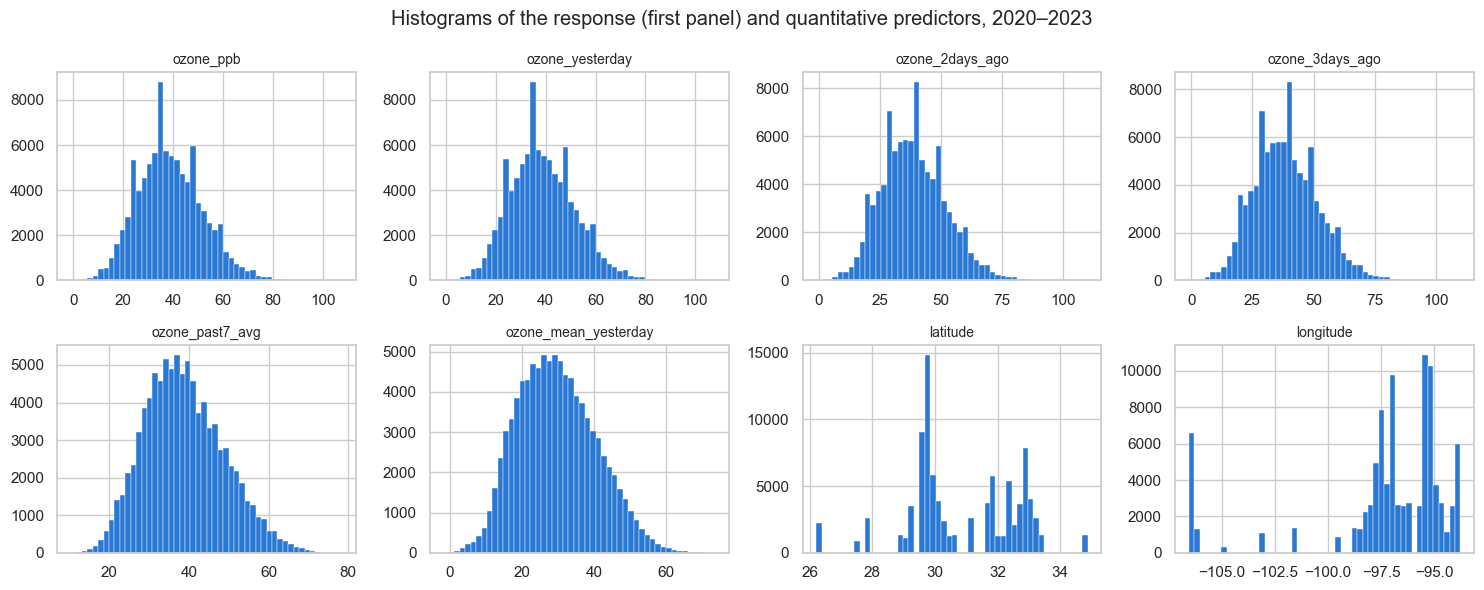

In [7]:
cols = ["ozone_ppb"] + quant
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, c in zip(axes.flat, cols):
    ax.hist(train[c], bins=50, color=ACTUAL_COLOR, edgecolor="white", linewidth=0.3)
    ax.set_title(c, fontsize=10)
plt.suptitle("Histograms of the response (first panel) and quantitative predictors, 2020–2023")
plt.tight_layout()
plt.savefig(f"{FIGS}/ozone_eda_histograms.png", dpi=150)
plt.show()


**What does this show?**
- **Ozone (the response)** is roughly bell-shaped, centered near 38 ppb, with a longer right tail (the high-ozone days).
- The past-ozone predictors have the same shape as the response, which is expected since they are the same measurement on earlier days.
- **Latitude and longitude** take only a few values, because they describe ~76 fixed sites, and the sites cluster around Houston, Dallas–Fort Worth, Austin/San Antonio and El Paso.
- No predictor is strongly skewed, so we have no reason yet to expect a linearity problem (LR slide 60).


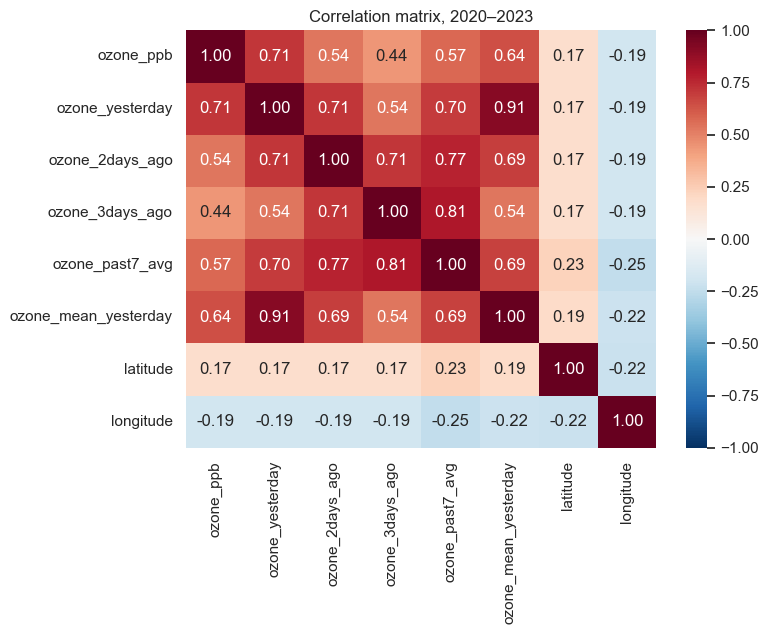

In [8]:
corr = train[cols].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation matrix, 2020–2023")
plt.tight_layout()
plt.savefig(f"{FIGS}/ozone_correlation_heatmap.png", dpi=150)
plt.show()


**What does this show?** (LR slide 84; VS slide 18: "good variables are highly correlated with the target but uncorrelated among themselves")
- **Correlation with the response (first row):** yesterday's ozone is the strongest (0.71). Next are yesterday's 24-hour mean (0.64), the past 7-day average (0.57), 2 days ago (0.54) and 3 days ago (0.44). Location is weak (|r| < 0.2).
- **Correlation among predictors:** the past-ozone predictors are strongly correlated with each other. Yesterday's MDA8 and yesterday's 24-hour mean have r = 0.91, and the 7-day average has r = 0.70–0.81 with the single days, because it *contains* them. This is a warning sign for **multicollinearity**, which we check with VIF in Section 7.


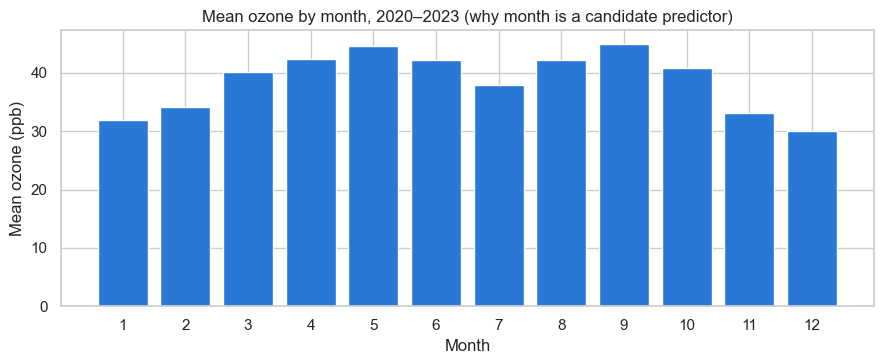

month,1,2,3,4,5,6,7,8,9,10,11,12
mean ozone (ppb),32.0,34.1,40.1,42.4,44.7,42.2,37.8,42.2,45.0,40.8,33.1,30.0


In [9]:
month_means = train.groupby("month")["ozone_ppb"].mean()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(month_means.index, month_means.values, color=ACTUAL_COLOR)
ax.set_xticks(range(1, 13))
ax.set_xlabel("Month")
ax.set_ylabel("Mean ozone (ppb)")
ax.set_title("Mean ozone by month, 2020–2023 (why month is a candidate predictor)")
plt.tight_layout()
plt.show()
month_means.round(1).to_frame("mean ozone (ppb)").T


Ozone has a clear **seasonal pattern**. It is lowest in December–January (~30–32 ppb), peaks in spring (May ≈ 45) and again in September (≈ 45), with a mid-summer dip in July. The pattern is not a straight line in month number, which is why we treat month as a **categorical** variable with dummy variables (LR slides 90–91) instead of a single number 1–12.


## 4. Simple linear regression (LR slides 19–22, 34–35)

We start with one predictor, the one most correlated with the response, yesterday's ozone:

$$Y = \beta_0 + \beta_1 \cdot \text{ozone\_yesterday} + \varepsilon$$

Ordinary least squares (OLS) picks $\hat\beta_0, \hat\beta_1$ to minimize the sum of squared vertical distances between the observed and fitted values (slide 19).

In [10]:
slr = smf.ols("ozone_ppb ~ ozone_yesterday", data=train).fit()
print(slr.summary().tables[1])
print(f"R-squared = {slr.rsquared:.3f}   residual standard error = {np.sqrt(slr.mse_resid):.2f} ppb")

                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          11.1189      0.094    118.358      0.000      10.935      11.303
ozone_yesterday     0.7134      0.002    310.671      0.000       0.709       0.718
R-squared = 0.509   residual standard error = 9.10 ppb



**Estimated regression line:** $\widehat{\text{ozone}} = 11.12 + 0.713 \times \text{ozone\_yesterday}$

**Interpreting the coefficients (LR slides 29, 35):**
- $\hat\beta_1 = 0.713$: each additional 1 ppb of ozone yesterday is associated with a **0.71 ppb** higher expected ozone today.
- $\hat\beta_0 = 11.12$: the expected ozone today if yesterday's ozone were 0. This is mainly a starting point for the line, because days with 0 ppb almost never happen.
- The slope is **less than 1**, so a high (or low) day tends to be followed by a day that is closer to the average.

**Significance:** t = 310.7, p ≈ 0, and the 95% confidence interval [0.709, 0.718] does not contain 0, so yesterday's ozone is statistically significant (LR slides 42–43).

**Fit:** R² = 0.509. Yesterday's ozone alone explains about **51%** of the variation in daily ozone. The residual standard error is 9.10 ppb.


## 5. Multiple linear regression with all candidate predictors (LR slides 23–29, 36–37)

$$Y = \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p + \varepsilon$$

`C(month)` tells statsmodels that month is **categorical**: it creates 11 dummy variables, and **January is the baseline** (LR slides 90–91). Each month coefficient is the expected difference from January, holding the other predictors fixed.

In [11]:
full_formula = ("ozone_ppb ~ ozone_yesterday + ozone_2days_ago + ozone_3days_ago + ozone_past7_avg"
                " + ozone_mean_yesterday + latitude + longitude + C(month) + weekend")
full = smf.ols(full_formula, data=train).fit()
print(full.summary())

                            OLS Regression Results                            
Dep. Variable:              ozone_ppb   R-squared:                       0.533
Model:                            OLS   Adj. R-squared:                  0.533
Method:                 Least Squares   F-statistic:                     5592.
Date:                Mon, 09 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:46:45   Log-Likelihood:            -3.3568e+05
No. Observations:               93175   AIC:                         6.714e+05
Df Residuals:                   93155   BIC:                         6.716e+05
Df Model:                          19                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept              -18.7972 


**Reading the output (LR slides 37, 45, 47, 83, 89):**

- **Overall F-test:** $H_0: \beta_1 = \dots = \beta_p = 0$. F = 5592 with p ≈ 0, so we reject $H_0$: at least one predictor is associated with ozone.
- **R² = 0.533, adjusted R² = 0.533.** The model explains 53.3% of the variation, up from 50.9% with yesterday alone. With 93,175 rows and 19 predictors, adjusted R² is almost the same as R².
- **t-tests:** every coefficient is significant at α = 0.05 except **weekend** (p = 0.19, its CI [−0.04, 0.21] contains 0) and the **November** dummy (p = 0.82, so November is not different from January). `ozone_3days_ago` is only borderline (p = 0.028).

**Interpreting the coefficients:** each one is the expected change in ozone for a one-unit change in that predictor, **holding all other predictors fixed** (LR slide 29):
- `ozone_yesterday` 0.672: still by far the strongest predictor.
- `ozone_past7_avg` 0.118: the recent weekly level adds information beyond yesterday.
- `ozone_2days_ago` −0.029 and `ozone_mean_yesterday` −0.087 are **negative**. This does *not* mean that more ozone two days ago lowers ozone today; see 5.1.
- **Month:** relative to January, expected ozone is about 3–4 ppb higher in March–May and in August–September, and 0.6 ppb lower in December. This matches the seasonal bar chart.
- **Location:** +0.32 ppb per degree of latitude (north) and −0.19 ppb per degree of longitude (a more negative longitude is further west, so ozone is slightly higher to the west).

**Warnings in the output:** the large condition number points to **multicollinearity** (Section 7). Jarque-Bera, Omnibus and Durbin-Watson are discussed in Section 9.


### 5.1 Marginal vs. conditional relationship (LR slides 38–39)
Simple regression gives the **marginal** association of a predictor with Y; multiple regression gives the **conditional** association, holding the other predictors fixed. These can differ in size and even in sign:

In [12]:
rows = []
for x in ["ozone_2days_ago", "ozone_3days_ago", "ozone_mean_yesterday"]:
    marginal = smf.ols(f"ozone_ppb ~ {x}", data=train).fit().params[x]
    rows.append([x, marginal, full.params[x]])
pd.DataFrame(rows, columns=["predictor", "marginal (simple regression)", "conditional (full model)"]).round(3)

,predictor,marginal (simple regression),conditional (full model)
0,ozone_2days_ago,0.536,-0.029
1,ozone_3days_ago,0.442,0.009
2,ozone_mean_yesterday,0.773,-0.087



On its own (marginally), ozone 2 days ago has a strong **positive** slope (0.54). In the multiple regression (conditionally on yesterday, the weekly average, etc.) its slope is about **zero or slightly negative** (−0.03). The same happens to yesterday's 24-hour mean (0.77 → −0.09).

As LR slide 39 says, *multiple regression coefficients must not be interpreted marginally.* Two days ago is related to today mainly **because** it is related to yesterday. Once yesterday is in the model, it has almost nothing new to say. This is also a symptom of correlated predictors.


## 6. Testing a subset of coefficients: partial F-test (LR slides 49–53, 101–102)

**Is month needed?** The 11 month dummies are a group, so we test them together:

- $H_0$: all 11 month coefficients = 0
- $H_a$: at least one is not 0

We compare the **reduced model** (no month) with the **full model**. We do the same for the simple regression vs. the full model (do the other predictors add anything beyond yesterday's ozone?).

In [13]:
reduced_no_month = smf.ols(full_formula.replace(" + C(month)", ""), data=train).fit()
print("Reduced (no month) vs. full model")
print(sm.stats.anova_lm(reduced_no_month, full))
print()
print("Simple regression (yesterday only) vs. full model")
print(sm.stats.anova_lm(slr, full))

Reduced (no month) vs. full model
   df_resid           ssr  df_diff       ss_diff           F  Pr(>F)
0   93166.0  7.504717e+06      0.0           NaN         NaN     NaN
1   93155.0  7.346447e+06     11.0  158270.12733  182.446321     0.0

Simple regression (yesterday only) vs. full model
   df_resid           ssr  df_diff        ss_diff           F  Pr(>F)
0   93173.0  7.723984e+06      0.0            NaN         NaN     NaN
1   93155.0  7.346447e+06     18.0  377536.926747  265.959664     0.0



**Month (11 dummies):** partial F = 182.4 on 11 and 93,155 degrees of freedom, p ≈ 0. We **reject $H_0$**: given the past-ozone and location predictors, season is still significantly associated with ozone, so we keep month.

**Simple vs. full model:** partial F = 266.0 on 18 and 93,155 df, p ≈ 0. The other 18 predictor terms together add significant explanatory power beyond yesterday's ozone (R² 0.509 → 0.533).

The F-statistic is computed exactly as on LR slide 101:
$F = \dfrac{(SSE_{reduced} - SSE_{full}) / q}{SSE_{full} / (n - p - 1)}$, where *q* is the number of coefficients being tested.


## 7. Multicollinearity: VIF (LR slides 84–88)

The past-day predictors overlap (the 7-day average *contains* yesterday, 2 and 3 days ago), so we check the **variance inflation factor**:

$$VIF_j = \frac{1}{1 - R_j^2}$$

where $R_j^2$ comes from regressing predictor *j* on all the other predictors. Following slide 88, a VIF is a concern if it is greater than $\max\left(10, \frac{1}{1 - R^2_{model}}\right)$.

In [14]:
X_vif = sm.add_constant(train[quant + ["weekend"]])
vif = pd.Series([variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])],
                index=X_vif.columns[1:], name="VIF")
threshold = max(10, 1 / (1 - full.rsquared))
print(f"Threshold = max(10, 1/(1 - {full.rsquared:.3f})) = {threshold:.1f}")
vif.round(2).to_frame()

Threshold = max(10, 1/(1 - 0.533)) = 10.0


,VIF
ozone_yesterday,6.35
ozone_2days_ago,3.17
ozone_3days_ago,3.16
ozone_past7_avg,4.43
ozone_mean_yesterday,5.88
latitude,1.09
longitude,1.11
weekend,1.00



**Result:** the largest VIFs are for yesterday's ozone (6.35) and yesterday's 24-hour mean (5.88). **All VIFs are below the threshold of 10**, so by the rule on LR slide 88 multicollinearity is **not severe**.

It is still there: yesterday's MDA8 and 24-hour mean have r = 0.91. That is why their conditional coefficients look odd (Section 5.1), and why the variable-selection step below is worthwhile. The model's **predictions** are not harmed much by moderate collinearity; it mainly makes the individual coefficients harder to interpret (LR slide 85).


## 8. Variable selection (Variable Selection deck)

Slide 4 of the VS deck lists three kinds of feature selection. We use one of each.

### 8.1 Filter methods (VS slides 8–11)
- **Basic method:** remove constant / quasi-constant predictors with `VarianceThreshold`.
- **Univariate selection:** `f_regression` gives each predictor's F-value against Y on its own.

In [15]:
X_dummies = pd.get_dummies(train[quant + ["weekend", "month"]], columns=["month"],
                           drop_first=True, dtype=float)
vt = VarianceThreshold(threshold=0.0).fit(X_dummies)
print("Constant predictors removed by VarianceThreshold:",
      list(X_dummies.columns[~vt.get_support()]) or "none")

F, p = f_regression(X_dummies, train["ozone_ppb"])
pd.DataFrame({"F-value": F.round(1), "p-value": p}, index=X_dummies.columns) \
  .sort_values("F-value", ascending=False).head(12)

Constant predictors removed by VarianceThreshold: none


,F-value,p-value
ozone_yesterday,96516.6,0.000000e+00
ozone_mean_yesterday,66315.5,0.000000e+00
ozone_past7_avg,45341.2,0.000000e+00
ozone_2days_ago,37601.6,0.000000e+00
ozone_3days_ago,22609.3,0.000000e+00
month_12,4170.0,0.000000e+00
longitude,3431.3,0.000000e+00
latitude,2938.3,0.000000e+00
month_9,1964.1,0.000000e+00
month_5,1847.5,0.000000e+00



- **Variance threshold:** no predictor is constant, so nothing is removed.
- **F-values:** ranking each predictor on its own, the past-ozone predictors score highest (yesterday's ozone first), followed by December, location and other months. Every p-value is essentially 0.

**Limitation (VS slides 6, 9):** filter methods score each predictor **alone**. They cannot see that 2 days ago is redundant once yesterday is known. They also do not use the model itself, which is why the slides say they usually perform worse than wrapper methods. We use them only as a first screen; every candidate passes.


### 8.2 Wrapper methods: forward selection and backward elimination (VS slides 22–31)

- **Forward selection** starts from the null model (intercept only) and adds the predictor that improves the criterion most, until nothing improves it.
- **Backward elimination** starts from the full model and removes the predictor whose removal improves the criterion most.

**Stopping rule.** With about 93,000 rows almost every p-value is tiny, so a fixed p-value threshold would keep everything. VS slide 25 also allows the threshold to be set by **AIC or BIC**, and we use those. Slide 28: BIC penalizes extra parameters more and picks the simplest model that reflects the process; AIC aims at the best prediction. Month is treated as **one** predictor (its 11 dummies enter or leave together).

In [16]:
candidates = ["ozone_yesterday", "ozone_2days_ago", "ozone_3days_ago", "ozone_past7_avg",
              "ozone_mean_yesterday", "latitude", "longitude", "C(month)", "weekend"]

def fit_ols(data, response, predictors):
    rhs = " + ".join(predictors) if predictors else "1"
    return smf.ols(f"{response} ~ {rhs}", data=data).fit()

def forward_selection(data, response, cands, criterion):
    chosen, steps = [], []
    best = getattr(fit_ols(data, response, chosen), criterion)
    while True:
        remaining = [c for c in cands if c not in chosen]
        if not remaining:
            break
        score, var = min((getattr(fit_ols(data, response, chosen + [v]), criterion), v) for v in remaining)
        if score >= best:
            break
        best = score
        chosen.append(var)
        steps.append(("add", var, round(score, 1)))
    return chosen, steps

def backward_elimination(data, response, cands, criterion):
    chosen, steps = list(cands), []
    best = getattr(fit_ols(data, response, chosen), criterion)
    while chosen:
        score, var = min((getattr(fit_ols(data, response, [c for c in chosen if c != v]), criterion), v)
                         for v in chosen)
        if score >= best:
            break
        best = score
        chosen.remove(var)
        steps.append(("remove", var, round(score, 1)))
    return chosen, steps

selection = {}
for crit in ["aic", "bic"]:
    for name, fn in [("forward", forward_selection), ("backward", backward_elimination)]:
        chosen, steps = fn(train, "ozone_ppb", candidates, crit)
        selection[(name, crit)] = chosen
        print(f"{name} selection, {crit.upper()}:")
        for s in steps:
            print(f"   {s[0]:6s} {s[1]:22s} {crit.upper()} = {s[2]}")
        print(f"   final: {chosen}\n")

forward selection, AIC:
   add    ozone_yesterday        AIC = 676033.6
   add    C(month)               AIC = 673285.4
   add    ozone_past7_avg        AIC = 672415.3
   add    longitude              AIC = 671927.5
   add    latitude               AIC = 671620.3
   add    ozone_mean_yesterday   AIC = 671448.0
   add    ozone_2days_ago        AIC = 671403.0
   add    ozone_3days_ago        AIC = 671400.0
   final: ['ozone_yesterday', 'C(month)', 'ozone_past7_avg', 'longitude', 'latitude', 'ozone_mean_yesterday', 'ozone_2days_ago', 'ozone_3days_ago']



backward selection, AIC:
   remove weekend                AIC = 671400.0
   final: ['ozone_yesterday', 'ozone_2days_ago', 'ozone_3days_ago', 'ozone_past7_avg', 'ozone_mean_yesterday', 'latitude', 'longitude', 'C(month)']



forward selection, BIC:
   add    ozone_yesterday        BIC = 676052.5
   add    C(month)               BIC = 673408.2
   add    ozone_past7_avg        BIC = 672547.5
   add    longitude              BIC = 672069.2
   add    latitude               BIC = 671771.4
   add    ozone_mean_yesterday   BIC = 671608.5
   add    ozone_2days_ago        BIC = 671573.0
   final: ['ozone_yesterday', 'C(month)', 'ozone_past7_avg', 'longitude', 'latitude', 'ozone_mean_yesterday', 'ozone_2days_ago']



backward selection, BIC:
   remove weekend                BIC = 671579.4
   remove ozone_3days_ago        BIC = 671573.0
   final: ['ozone_yesterday', 'ozone_2days_ago', 'ozone_past7_avg', 'ozone_mean_yesterday', 'latitude', 'longitude', 'C(month)']




**What happened:**
- **Forward selection** added yesterday's ozone first, then month, the 7-day average, longitude, latitude, yesterday's 24-hour mean, and 2 days ago. The first few additions drop AIC/BIC by thousands; the last ones by only tens.
- **Backward elimination** removed **weekend** first under both criteria. BIC also removed **3 days ago**.
- **AIC** keeps 8 predictors (everything except weekend). **BIC** keeps 7 (it also drops 3 days ago), because it penalizes extra parameters more (VS slide 26).
- **Forward and backward selection with BIC agree** on the same 7 predictors, which is reassuring (VS slide 31: "best of both worlds").


### 8.3 Embedded method: Lasso (VS slides 42, 46–50)

Lasso adds an L1 penalty $\lambda \sum |\beta_j|$ to the least-squares objective, which can shrink coefficients **exactly to zero** (removing those predictors). The predictors are standardized first so the penalty treats all coefficients on the same scale. We choose $\lambda$ with **BIC** (VS slides 26–28) using `LassoLarsIC`, and also plot the **Lasso path**: how each coefficient shrinks as $\lambda$ grows (VS slide 50).

lambda chosen by BIC: 0.0
coefficients set to zero: none


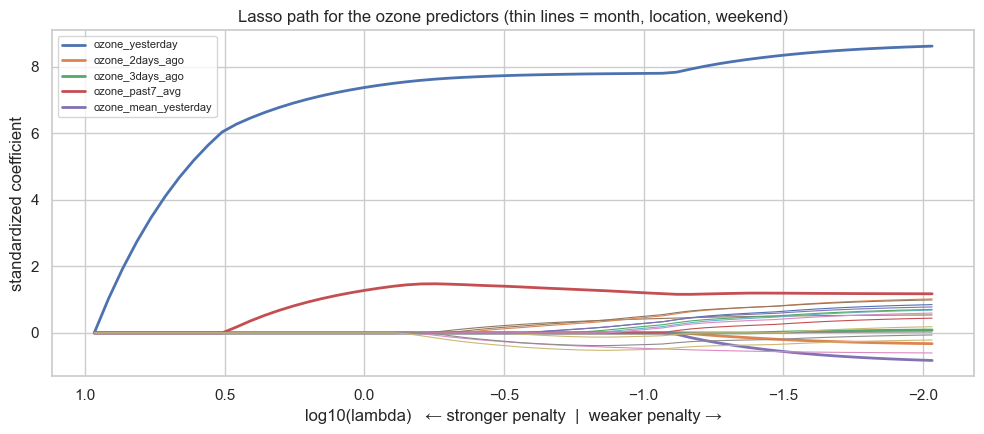

Order in which predictors ENTER the Lasso path (first = most important):
ozone_yesterday    0.92
ozone_past7_avg    0.46
month_12          -0.15
longitude         -0.20
latitude          -0.25
month_11          -0.25


In [17]:
scaler = StandardScaler().fit(X_dummies)
Xs = scaler.transform(X_dummies)
y_tr = train["ozone_ppb"].values

lasso_bic = LassoLarsIC(criterion="bic").fit(Xs, y_tr)
print("lambda chosen by BIC:", lasso_bic.alpha_)
print("coefficients set to zero:", list(X_dummies.columns[lasso_bic.coef_ == 0]) or "none")

alphas, coefs, _ = lasso_path(Xs, y_tr - y_tr.mean(), n_alphas=60)
fig, ax = plt.subplots(figsize=(10, 4.5))
for name, path in zip(X_dummies.columns, coefs):
    lw = 2 if name.startswith("ozone") else 0.8
    ax.plot(np.log10(alphas), path, linewidth=lw, label=name if name.startswith("ozone") else None)
ax.invert_xaxis()
ax.set_xlabel("log10(lambda)   ← stronger penalty  |  weaker penalty →")
ax.set_ylabel("standardized coefficient")
ax.set_title("Lasso path for the ozone predictors (thin lines = month, location, weekend)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{FIGS}/ozone_lasso_path.png", dpi=150)
plt.show()

order_zero = pd.Series({n: np.log10(alphas[np.nonzero(c)[0][0]]) if np.any(c) else np.nan
                        for n, c in zip(X_dummies.columns, coefs)})
print("Order in which predictors ENTER the Lasso path (first = most important):")
print(order_zero.sort_values(ascending=False).head(6).round(2).to_string())


**What happened:** BIC chose **λ = 0**, meaning no shrinkage. With about 93,000 observations and only 19 coefficients, the least-squares estimates are already very stable, so a penalty only adds bias (VS slide 50: "as λ increases, bias increases"). Lasso therefore removes no predictors here.

The **Lasso path** is still useful. It shows the **order of importance**: as λ is lowered from very large, **yesterday's ozone** is the first coefficient to become non-zero, then the **7-day average**, then December and location. This matches the forward selection order.


### 8.4 The selected model
We use the **BIC** model as the final model (smallest model that all methods support). Below is its fit.

In [18]:
final_predictors = selection[("backward", "bic")]
final_formula = "ozone_ppb ~ " + " + ".join(final_predictors)
print(final_formula)
final = smf.ols(final_formula, data=train).fit()
print(final.summary())

ozone_ppb ~ ozone_yesterday + ozone_2days_ago + ozone_past7_avg + ozone_mean_yesterday + latitude + longitude + C(month)


                            OLS Regression Results                            
Dep. Variable:              ozone_ppb   R-squared:                       0.533
Model:                            OLS   Adj. R-squared:                  0.533
Method:                 Least Squares   F-statistic:                     6249.
Date:                Mon, 09 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:47:16   Log-Likelihood:            -3.3568e+05
No. Observations:               93175   AIC:                         6.714e+05
Df Residuals:                   93157   BIC:                         6.716e+05
Df Model:                          17                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept              -18.7336 


**Final model (selected by BIC):**

ozone = −18.73 + 0.671·yesterday − 0.026·(2 days ago) + 0.126·(past 7-day avg) − 0.086·(yesterday's 24-h mean) + 0.319·latitude − 0.189·longitude + month effect

where the month effect, relative to January, is: Feb +0.98, Mar +2.73, Apr +3.35, May +3.91, Jun +2.82, Jul +1.85, Aug +3.05, Sep +3.86, Oct +2.37, Nov −0.04, Dec −0.58 ppb.

- Overall F = 6249, p ≈ 0. Every remaining quantitative predictor has p < 0.001.
- R² = 0.533 and adjusted R² = 0.533, the same as the full model with 2 fewer predictors.
- **Interpretation:** holding the other predictors fixed, a 10 ppb higher ozone yesterday goes with about **6.7 ppb** higher expected ozone today. A 10 ppb higher weekly average adds another **1.3 ppb**. Spring and September days run 3–4 ppb above an otherwise identical January day.


In [19]:
print("Partial F-test: final (reduced) model vs. full model")
print(sm.stats.anova_lm(final, full))
print()
cmp = pd.DataFrame({
    "predictors (df)": [slr.df_model, full.df_model, final.df_model],
    "R²": [slr.rsquared, full.rsquared, final.rsquared],
    "adjusted R²": [slr.rsquared_adj, full.rsquared_adj, final.rsquared_adj],
    "AIC": [slr.aic, full.aic, final.aic],
    "BIC": [slr.bic, full.bic, final.bic],
}, index=["simple (yesterday only)", "full (all candidates)", "final (BIC selected)"])
cmp.round(4)

Partial F-test: final (reduced) model vs. full model
   df_resid           ssr  df_diff     ss_diff         F    Pr(>F)
0   93157.0  7.346973e+06      0.0         NaN       NaN       NaN
1   93155.0  7.346447e+06      2.0  526.843641  3.340262  0.035432



,predictors (df),R²,adjusted R²,AIC,BIC
simple (yesterday only),1.0,0.5088,0.5088,676033.6409,676052.5253
full (all candidates),19.0,0.5328,0.5327,671400.3163,671589.1610
final (BIC selected),17.0,0.5328,0.5327,671402.9980,671572.9583



**Comparing models (LR slide 114: "compare models with ANOVA or adjusted R²"):**
- **Final vs. full:** dropping weekend and 3 days ago gives a partial F = 3.34, p = 0.035. At α = 0.05 the test still says the two dropped variables add *something*, but it is tiny. The sum of squared errors grows by 0.007%, adjusted R² is unchanged (0.5327), and BIC prefers the smaller model. **With n ≈ 93,000, even negligible effects become "significant"**, which is exactly why VS slide 25 suggests AIC/BIC rather than a fixed p-value threshold. We keep the simpler BIC model.
- **Final vs. simple:** adjusted R² rises from 0.509 to 0.533, and AIC/BIC drop by about 4,500. The extra predictors are worth keeping.


## 9. Checking the assumptions: residual analysis (LR slides 57–68, 80–81, 89, 105–106, 113)

| Assumption | How we check it (LR slide 113) |
|---|---|
| Linearity | residuals vs. **each** predictor |
| Constant variance | residuals vs. fitted values; Breusch-Pagan test |
| Uncorrelated errors | Durbin-Watson (≈ 2 is ideal) |
| Normality | histogram and QQ plot of the residuals; Jarque-Bera test |

The residuals are put in site-and-date order first, so Durbin-Watson compares each day with the next day at the same site.

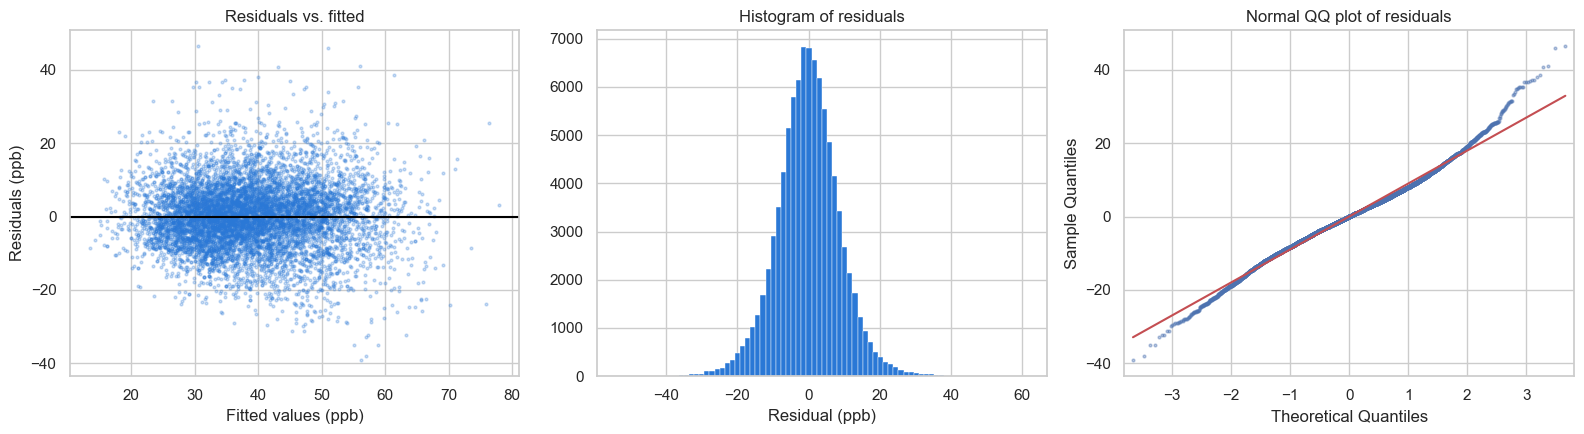

In [20]:
resid = final.resid
fitted = final.fittedvalues
rng = np.random.default_rng(0)
sample = rng.choice(len(resid), 8000, replace=False)   # plot a random sample so the dots are readable

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(fitted.iloc[sample], resid.iloc[sample], s=4, alpha=0.25, color=ACTUAL_COLOR)
axes[0].axhline(0, color="black")
axes[0].set_xlabel("Fitted values (ppb)"); axes[0].set_ylabel("Residuals (ppb)")
axes[0].set_title("Residuals vs. fitted")
axes[1].hist(resid, bins=80, color=ACTUAL_COLOR, edgecolor="white", linewidth=0.3)
axes[1].set_title("Histogram of residuals"); axes[1].set_xlabel("Residual (ppb)")
sm.qqplot(resid.iloc[sample], line="s", ax=axes[2], markersize=2, alpha=0.4)
axes[2].set_title("Normal QQ plot of residuals")
plt.tight_layout()
plt.savefig(f"{FIGS}/ozone_residual_diagnostics.png", dpi=150)
plt.show()

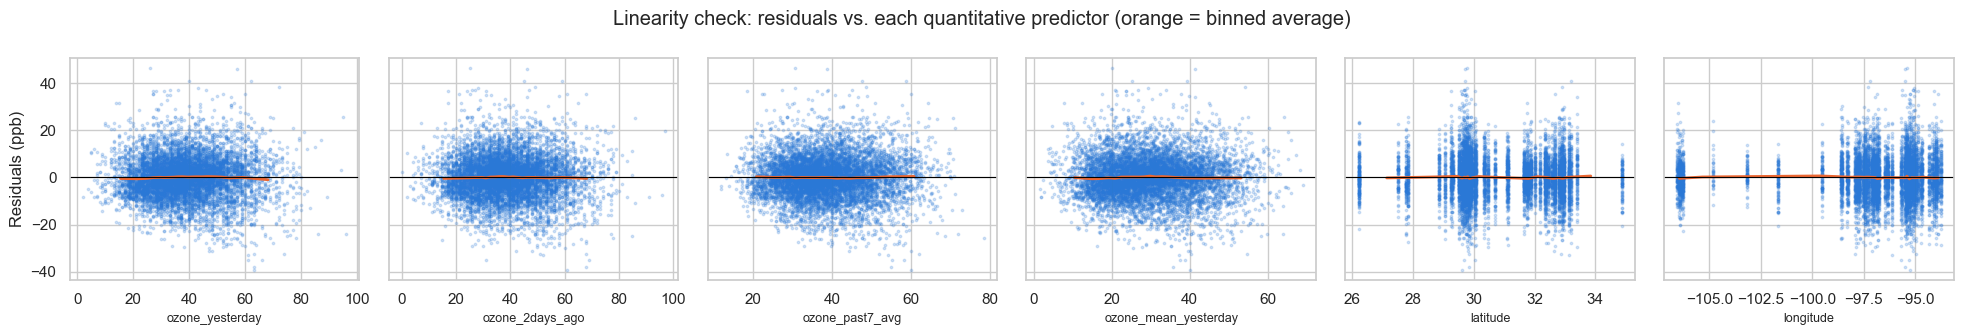

In [21]:
quant_final = [c for c in final_predictors if c in quant]
fig, axes = plt.subplots(1, len(quant_final), figsize=(3.3 * len(quant_final), 3.4), sharey=True)
for ax, c in zip(axes, quant_final):
    ax.scatter(train[c].iloc[sample], resid.iloc[sample], s=3, alpha=0.2, color=ACTUAL_COLOR)
    # average residual in 20 bins of the predictor, to make any curve easy to see
    bins = pd.qcut(train[c], 20, duplicates="drop")
    binned = pd.DataFrame({"x": train[c], "r": resid}).groupby(bins, observed=True).mean()
    ax.plot(binned["x"], binned["r"], color=PREDICT_COLOR, linewidth=2)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xlabel(c, fontsize=9)
axes[0].set_ylabel("Residuals (ppb)")
plt.suptitle("Linearity check: residuals vs. each quantitative predictor (orange = binned average)")
plt.tight_layout()
plt.savefig(f"{FIGS}/ozone_residuals_vs_predictors.png", dpi=150)
plt.show()

In [22]:
def assumption_tests(model, order_df):
    r = model.resid
    jb, jb_p, skew, kurt = jarque_bera(r)
    bp_lm, bp_p, _, _ = het_breuschpagan(r, model.model.exog)
    dw = durbin_watson(r.loc[order_df.sort_values(["site_id", "date"]).index])
    return pd.DataFrame({
        "statistic": [jb, skew, kurt, bp_lm, dw],
        "p-value": [jb_p, np.nan, np.nan, bp_p, np.nan],
    }, index=["Jarque-Bera (normality)", "  skew (normal = 0)", "  kurtosis (normal = 3)",
              "Breusch-Pagan (constant variance)", "Durbin-Watson (independence, ideal ≈ 2)"])

assumption_tests(final, train).round(4)

,statistic,p-value
Jarque-Bera (normality),6095.7431,0.0
skew (normal = 0),0.0643,NaN
kurtosis (normal = 3),4.2464,NaN
Breusch-Pagan (constant variance),5277.6198,0.0
"Durbin-Watson (independence, ideal ≈ 2)",2.0004,NaN



**Results:**

| Assumption | Evidence | Conclusion |
|---|---|---|
| **Linearity** | The residual-vs-predictor curves stay close to 0. Yesterday's ozone shows a slight bend at the high end, where the binned average residual dips. | Holds well, with a small curve for yesterday (tested in 10.2) |
| **Constant variance** | Residuals vs. fitted is a mild fan: the spread is smaller at low fitted values (clean days) than at middle-to-high ones. Breusch-Pagan LM = 5,278, p ≈ 0 | **Does not fully hold**: errors are bigger on higher-ozone days (like LR slide 63) |
| **Uncorrelated errors** | Durbin-Watson = 2.00 | **Holds**: including yesterday's value removed the day-to-day correlation |
| **Normality** | The histogram is symmetric (skew 0.06) but has heavier tails than normal (kurtosis 4.25 vs. 3), and the QQ plot curves at both ends. Jarque-Bera p ≈ 0 | **Approximately** normal, with heavy tails (like LR slide 107) |

**About the p-values:** with 93,000 residuals, Jarque-Bera and Breusch-Pagan reject even very small departures. The plots show the residuals are symmetric and centered at 0. The main real issue is **non-constant variance**, which makes the prediction intervals too narrow on high days and too wide on low days (Section 12).


## 10. Transformations (LR slides 15–16, 69–70)

### 10.1 Box-Cox transformation of the response
Slide 70: if normality or constant variance does not hold, transform $y \to y^\lambda$ and let software estimate λ. Box-Cox needs $y > 0$, so the few site-days with ozone ≤ 0 ppb are left out of this step.

In [23]:
pos = train[train["ozone_ppb"] > 0].copy()
print("Site-days with ozone <= 0 left out:", len(train) - len(pos))
_, lam = stats.boxcox(pos["ozone_ppb"])
print(f"Box-Cox lambda estimated by scipy: {lam:.3f}")

Site-days with ozone <= 0 left out: 4


Box-Cox lambda estimated by scipy: 0.651



λ = 0.65. In the Box-Cox table on LR slide 70, the closest common transformation is **λ = 0.5, the square root**. We refit the final model on √ozone and compare the assumption checks.


In [24]:
# square-root response, and the same transform on the past-ozone predictors so they stay on the same scale
pos["sqrt_ozone"] = np.sqrt(pos["ozone_ppb"])
past_cols = [c for c in final_predictors if c.startswith("ozone")]
for c in past_cols:
    pos[f"sqrt_{c}"] = np.sqrt(pos[c].clip(lower=0))
sqrt_rhs = [f"sqrt_{c}" if c in past_cols else c for c in final_predictors]
sqrt_model = smf.ols("sqrt_ozone ~ " + " + ".join(sqrt_rhs), data=pos).fit()
final_pos = smf.ols(final_formula, data=pos).fit()   # untransformed model on the same rows

pd.concat({"original scale": assumption_tests(final_pos, pos)["statistic"],
           "square-root scale": assumption_tests(sqrt_model, pos)["statistic"]}, axis=1).round(3)

,original scale,square-root scale
Jarque-Bera (normality),6098.706,9531.713
skew (normal = 0),0.065,-0.386
kurtosis (normal = 3),4.247,4.363
Breusch-Pagan (constant variance),5283.735,3222.093
"Durbin-Watson (independence, ideal ≈ 2)",2.000,2.000



**Did the transformation help?**
- **Constant variance improved:** Breusch-Pagan dropped from 5,284 to 3,222. The square root shrinks the large values, so the fan in the residuals is narrower.
- **Normality got worse:** skew went from +0.07 to −0.39 and Jarque-Bera rose from 6,099 to 9,532. The original residuals were already symmetric, and the square root over-corrected them.
- Durbin-Watson stays at 2.00.

Because the transformation fixes one assumption but breaks another, and makes the coefficients harder to explain (they are on a √ppb scale), **we keep ozone in its original units**. We remember that the variance is not constant when we read the prediction intervals.


### 10.2 A second-order term? (LR slides 15–16)
If the residuals-vs-predictor plot of yesterday's ozone bends, a squared term (a 2nd-order / polynomial model) can capture it. We test it with the t-test of the new coefficient and the change in adjusted R².

In [25]:
quad = smf.ols(final_formula + " + I(ozone_yesterday ** 2)", data=train).fit()
print(quad.summary().tables[1].data[-1])
print(f"adjusted R²: final = {final.rsquared_adj:.4f}, with squared term = {quad.rsquared_adj:.4f}")
print(f"BIC:         final = {final.bic:.1f}, with squared term = {quad.bic:.1f}")

# does it predict 2024 better?
y24 = test["ozone_ppb"].values
for name, m in [("final", final), ("with squared term", quad)]:
    p24 = m.predict(test).values
    print(f"R² on 2024, {name}: {1 - ((y24 - p24) ** 2).sum() / ((y24 - y24.mean()) ** 2).sum():.4f}")

['I(ozone_yesterday ** 2)', '   -0.0016', '    0.000', '  -12.585', ' 0.000', '   -0.002', '   -0.001']
adjusted R²: final = 0.5327, with squared term = 0.5335
BIC:         final = 671573.0, with squared term = 671426.1
R² on 2024, final: 0.5311
R² on 2024, with squared term: 0.5323



The squared term is significant (t = −12.6) and BIC is lower (671,426 vs. 671,573), so it captures the slight bend seen in the residuals-vs-yesterday plot. The negative sign means that **at very high levels, each extra ppb of ozone yesterday carries over a bit less**.

The practical gain, however, is very small. Adjusted R² rises only from 0.5327 to 0.5335, and R² on the 2024 data only from 0.531 to 0.532. Following "all models are wrong, but some are useful" (LR slide 24) and the VS slide 3 point that simpler models are easier to interpret, we **keep the linear (first-order) model** and note this as a possible refinement.


## 11. Outliers and influential points: Cook's distance (LR slides 72–76)

Cook's distance measures how much **all** fitted values change when one observation is removed. Rule of thumb (slide 75): look at points with $D_i > 4/n$, and treat $D_i > 1$ as clearly influential.

n = 93175,  4/n = 0.000043
Site-days with D > 4/n: 5038 (5.4%)
Site-days with D > 1:   0
Largest Cook's distance: 0.00101


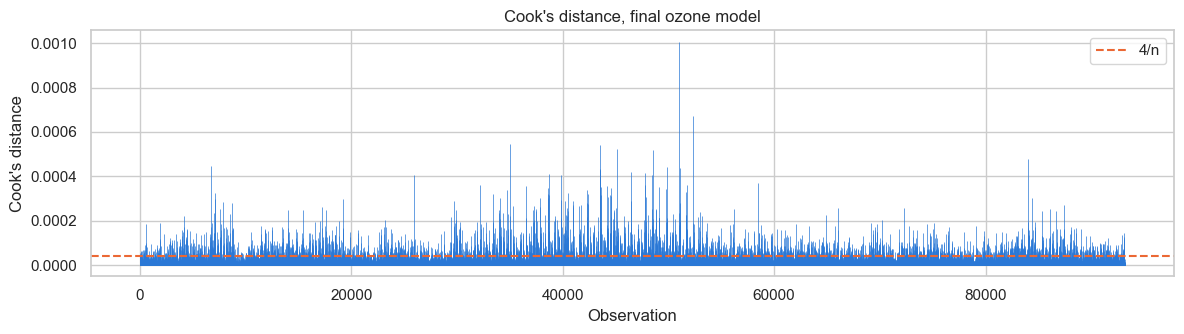

,site_id,local_site_name,date,ozone_ppb,ozone_yesterday,ozone_past7_avg,cook
68937,48-201-1039,Houston Deer Park #2,2021-06-20,20.0,89.0,68.7143,0.0010
70705,48-201-1050,Seabrook Friendship Park,2021-06-20,17.0,79.0,61.2000,0.0007
47007,48-201-0029,Northwest Harris County,2022-05-07,42.0,91.0,43.0000,0.0005
58784,48-201-0416,Park Place,2021-06-22,67.0,17.0,60.2857,0.0005
60827,48-201-0417,Houston Harvard Street,2023-05-18,108.0,51.0,35.8571,0.0005


In [26]:
cook = final.get_influence().cooks_distance[0]
n = len(train)
print(f"n = {n},  4/n = {4 / n:.6f}")
print(f"Site-days with D > 4/n: {(cook > 4 / n).sum()} ({(cook > 4 / n).mean() * 100:.1f}%)")
print(f"Site-days with D > 1:   {(cook > 1).sum()}")
print(f"Largest Cook's distance: {cook.max():.5f}")

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.vlines(np.arange(n), 0, cook, linewidth=0.5, color=ACTUAL_COLOR)
ax.axhline(4 / n, color=PREDICT_COLOR, linestyle="--", label="4/n")
ax.set_xlabel("Observation"); ax.set_ylabel("Cook's distance")
ax.set_title("Cook's distance, final ozone model")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIGS}/ozone_cooks_distance.png", dpi=150)
plt.show()

top = train.assign(cook=cook).nlargest(5, "cook")
top[["site_id", "local_site_name", "date", "ozone_ppb", "ozone_yesterday", "ozone_past7_avg", "cook"]].round(4)


**Result:**
- **No influential points:** the largest Cook's distance is 0.001, about 1,000 times smaller than the D > 1 cutoff.
- About 5.4% of site-days have D > 4/n. With n = 93,175, the 4/n cutoff (0.00004) is extremely small, so it flags many ordinary points.
- **The top points are real events, not data errors.** For example, at Houston Deer Park on 2021-06-20 ozone fell from 89 ppb to 20 ppb in one day, and at Houston Harvard Street on 2023-05-18 it jumped from 51 to 108 ppb. These are sudden weather changes (a front, or a stagnant hot day).

LR slide 72 says outliers should be examined but sometimes belong in the data. These do, so **we keep all observations**.


## 12. Predicting new responses: 2024 (LR slides 54–56, 82)

2024 days are **new observations**, so we use **prediction** (slide 54). A prediction has two sources of uncertainty (slide 55): the new observation's own randomness ($\sigma^2$) and the uncertainty in the estimated β's. So for each day we report the predicted value **and a 95% prediction interval**.

To measure how good the predictions are, we use the same quantities as for the fitted model, computed on the 2024 data:
- $R^2 = 1 - SSE/SST$ (slide 82): the share of the 2024 variation explained
- $\sqrt{MSE}$: the typical prediction error in ppb (comparable to the residual standard error)
- how many 2024 values fall inside their 95% prediction interval (should be close to 95%)

In [27]:
def prediction_report(model, new, response):
    pred = model.get_prediction(new).summary_frame(alpha=0.05)
    y = new[response].values
    sse = ((y - pred["mean"].values) ** 2).sum()
    sst = ((y - y.mean()) ** 2).sum()
    inside = (y >= pred["obs_ci_lower"].values) & (y <= pred["obs_ci_upper"].values)
    return pred, {"R² (1 - SSE/SST)": 1 - sse / sst,
                  "sqrt(MSE)": np.sqrt(sse / len(y)),
                  "inside 95% prediction interval": inside.mean()}

pred_final, rep_final = prediction_report(final, test, "ozone_ppb")
_, rep_slr = prediction_report(slr, test, "ozone_ppb")
_, rep_full = prediction_report(full, test, "ozone_ppb")

pred_table = pd.DataFrame({
    "simple (yesterday only)": {"R² on 2020–2023": slr.rsquared, **rep_slr},
    "full (all candidates)": {"R² on 2020–2023": full.rsquared, **rep_full},
    "final (BIC selected)": {"R² on 2020–2023": final.rsquared, **rep_final},
}).T
print("residual standard error of the final model on 2020–2023:", round(np.sqrt(final.mse_resid), 2), "ppb")
pred_table.round(3)

residual standard error of the final model on 2020–2023: 8.88 ppb


,R² on 2020–2023,R² (1 - SSE/SST),sqrt(MSE),inside 95% prediction interval
simple (yesterday only),0.509,0.504,9.325,0.939
full (all candidates),0.533,0.531,9.067,0.940
final (BIC selected),0.533,0.531,9.067,0.940



**How well does the model predict 2024, a year it never saw?**
- **R² on 2024 = 0.531**, almost identical to the 0.533 on 2020–2023. The model explains about **53% of the variation in new data** and is not overfitting.
- **√MSE = 9.07 ppb**, close to the residual standard error of 8.88 ppb. A typical prediction is off by about 9 ppb, on days that average 40 ppb.
- **94.0% of 2024 values fall inside their 95% prediction interval**, close to the promised 95%. This means the intervals are reasonable *on average*.
- The **simple** model (yesterday only) predicts almost as well (R² 0.504). The extra predictors add about 3 percentage points. The final BIC model predicts exactly as well as the full model with 2 fewer predictors.


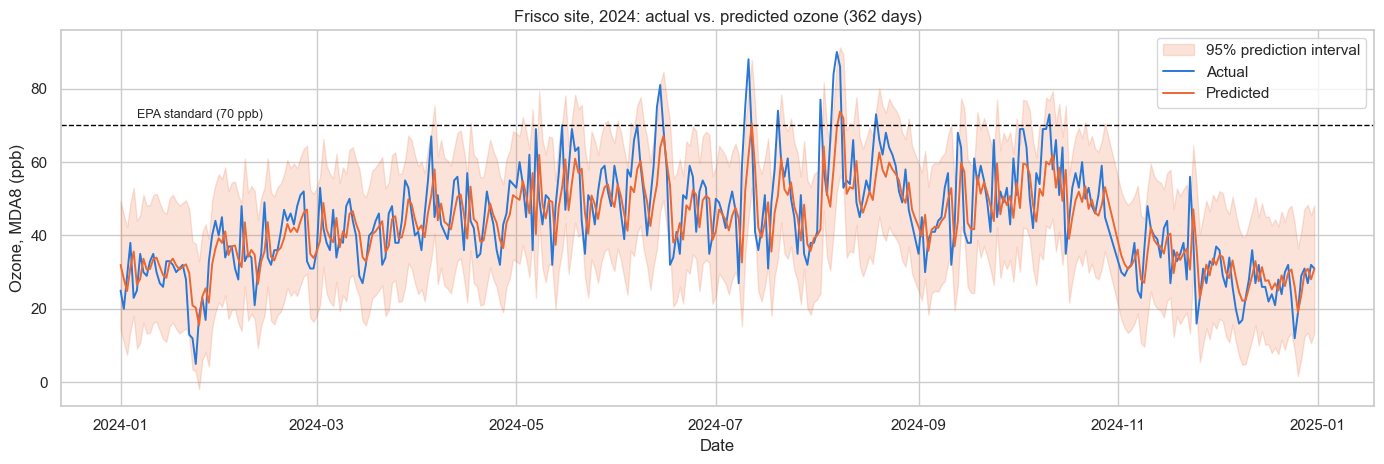

In [28]:
compare = test[["site_id", "local_site_name", "date", "ozone_ppb"]].copy()
compare["predicted"] = pred_final["mean"].values
compare["pi_low"] = pred_final["obs_ci_lower"].values
compare["pi_high"] = pred_final["obs_ci_upper"].values

site = "48-085-0005"   # Frisco (Dallas–Fort Worth), almost complete 2024 record
one = compare[compare["site_id"] == site]
fig, ax = plt.subplots(figsize=(14, 4.8))
ax.fill_between(one["date"], one["pi_low"], one["pi_high"], color=PREDICT_COLOR, alpha=0.18,
                label="95% prediction interval")
ax.plot(one["date"], one["ozone_ppb"], color=ACTUAL_COLOR, linewidth=1.4, label="Actual")
ax.plot(one["date"], one["predicted"], color=PREDICT_COLOR, linewidth=1.4, label="Predicted")
ax.axhline(70, color="black", linestyle="--", linewidth=1)
ax.text(one["date"].iloc[5], 72, "EPA standard (70 ppb)", fontsize=9)
ax.set_title(f"{one['local_site_name'].iloc[0]} site, 2024: actual vs. predicted ozone ({len(one)} days)")
ax.set_xlabel("Date"); ax.set_ylabel("Ozone, MDA8 (ppb)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(f"{FIGS}/ozone_actual_vs_predicted_frisco_2024.png", dpi=150)
plt.show()


**What does this show?** (Frisco, Dallas–Fort Worth, 2024)
- The predicted line (orange) follows the **seasonal pattern** of the actual line (blue): low in winter, higher in spring and late summer.
- The predictions are **smoother** than reality and usually **one day late**. When ozone jumps, the model only reacts the next day, because its main input is yesterday's value.
- The shaded 95% prediction interval contains most of the actual days, but the **highest peaks poke above it**.


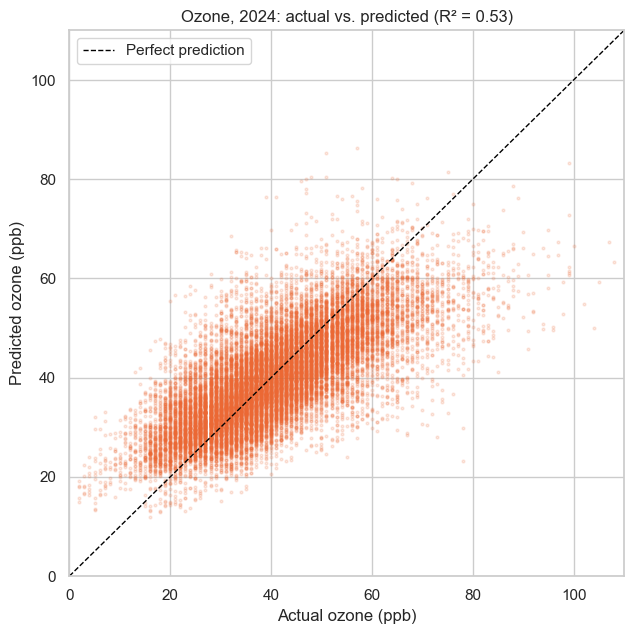

High-ozone days that were also PREDICTED >= 70 ppb: 14 of 560


,site-days,mean actual (ppb),mean predicted (ppb),inside 95% PI
actual ≥ 70 ppb,560,77.041,55.424,0.357
actual < 70 ppb,22278,39.493,39.497,0.955


In [29]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(compare["ozone_ppb"], compare["predicted"], s=4, alpha=0.15, color=PREDICT_COLOR)
ax.plot([0, 110], [0, 110], color="black", linestyle="--", linewidth=1, label="Perfect prediction")
ax.set_xlim(0, 110); ax.set_ylim(0, 110)
ax.set_title(f"Ozone, 2024: actual vs. predicted (R² = {rep_final['R² (1 - SSE/SST)']:.2f})")
ax.set_xlabel("Actual ozone (ppb)"); ax.set_ylabel("Predicted ozone (ppb)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(f"{FIGS}/ozone_actual_vs_predicted_scatter.png", dpi=150)
plt.show()

high = compare["ozone_ppb"] >= 70
inside_pi = (compare["ozone_ppb"] >= compare["pi_low"]) & (compare["ozone_ppb"] <= compare["pi_high"])
print("High-ozone days that were also PREDICTED >= 70 ppb:", (compare.loc[high, "predicted"] >= 70).sum(), "of", high.sum())
pd.DataFrame({
    "site-days": [high.sum(), (~high).sum()],
    "mean actual (ppb)": [compare.loc[high, "ozone_ppb"].mean(), compare.loc[~high, "ozone_ppb"].mean()],
    "mean predicted (ppb)": [compare.loc[high, "predicted"].mean(), compare.loc[~high, "predicted"].mean()],
    "inside 95% PI": [inside_pi[high].mean(), inside_pi[~high].mean()],
}, index=["actual ≥ 70 ppb", "actual < 70 ppb"]).round(3)


**What does this show?**
- **Scatter plot:** the points follow the diagonal, but the cloud is **flatter** than the diagonal. The model over-predicts very clean days and under-predicts high days, because predictions are pulled toward the average.
- **High-ozone days (≥ 70 ppb, the EPA standard)** are the model's biggest weakness. On the 560 such site-days in 2024, actual ozone averaged **77.0 ppb** but predictions averaged only **55.4 ppb**. Only **14 of 560** were predicted at ≥ 70 ppb, and only **36%** fell inside their 95% prediction interval, compared with 95.5% on normal days.
- This is the **non-constant variance** found in Section 9 showing up in practice. The intervals use one average σ, which is too small for high days. High-ozone days are driven mostly by **weather** (heat, sunshine, calm wind), which is not in our data.


## 13. Same steps for PM2.5

Same procedure for PM2.5 (`pm25_ugm3`, daily average in µg/m³):
candidates = PM2.5 yesterday, 2 and 3 days ago, past 7-day average, latitude, longitude, month (categorical), weekend → fit the full model → BIC backward elimination → diagnostics → Box-Cox → prediction intervals for 2024.

In [30]:
pm = pd.read_csv(f"{DATA}/Cleaned_Data/Texas_PM25_Clean.csv")
pm["date"] = pd.to_datetime(pm["date_local"])
pm = pm.sort_values(["site_id", "date"]).reset_index(drop=True)
pm = add_history(pm, "pm25_ugm3", "pm25")

pm_quant = ["pm25_yesterday", "pm25_2days_ago", "pm25_3days_ago", "pm25_past7_avg", "latitude", "longitude"]
pm_model = pm.dropna(subset=pm_quant).copy()
pm_train = pm_model[pm_model["year"] <= 2023].copy()
pm_test = pm_model[pm_model["year"] == 2024].copy()
print("Site-days kept:", len(pm_model), "of", len(pm), "| train:", len(pm_train), "| test:", len(pm_test))
print(pm_train[["pm25_ugm3"] + pm_quant].corr().round(2)["pm25_ugm3"])

Site-days kept: 71168 of 76660 | train: 54669 | test: 16499
pm25_ugm3         1.00
pm25_yesterday    0.64
pm25_2days_ago    0.39
pm25_3days_ago    0.33
pm25_past7_avg    0.48
latitude         -0.09
longitude         0.13
Name: pm25_ugm3, dtype: float64


In [31]:
pm_candidates = pm_quant + ["C(month)", "weekend"]
pm_full = fit_ols(pm_train, "pm25_ugm3", pm_candidates)
pm_selected, pm_steps = backward_elimination(pm_train, "pm25_ugm3", pm_candidates, "bic")
print("Backward elimination with BIC removed:", [s[1] for s in pm_steps] or "nothing")
pm_final = fit_ols(pm_train, "pm25_ugm3", pm_selected)
print(pm_final.summary())

Backward elimination with BIC removed: nothing
                            OLS Regression Results                            
Dep. Variable:              pm25_ugm3   R-squared:                       0.433
Model:                            OLS   Adj. R-squared:                  0.433
Method:                 Least Squares   F-statistic:                     2316.
Date:                Mon, 09 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:47:26   Log-Likelihood:            -1.5254e+05
No. Observations:               54669   AIC:                         3.051e+05
Df Residuals:                   54650   BIC:                         3.053e+05
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------

In [32]:
X_vif = sm.add_constant(pm_train[[c for c in pm_quant + ["weekend"] if c in pm_selected]])
print("VIF:", {c: round(variance_inflation_factor(X_vif.values, i), 2) for i, c in enumerate(X_vif.columns) if c != "const"})
assumption_tests(pm_final, pm_train).round(4)

VIF: {'pm25_yesterday': np.float64(2.03), 'pm25_2days_ago': np.float64(2.56), 'pm25_3days_ago': np.float64(2.54), 'pm25_past7_avg': np.float64(3.58), 'latitude': np.float64(1.03), 'longitude': np.float64(1.05), 'weekend': np.float64(1.0)}


,statistic,p-value
Jarque-Bera (normality),1.177502e+06,0.0
skew (normal = 0),2.052500e+00,NaN
kurtosis (normal = 3),2.536250e+01,NaN
Breusch-Pagan (constant variance),1.942914e+03,0.0
"Durbin-Watson (independence, ideal ≈ 2)",2.001700e+00,NaN


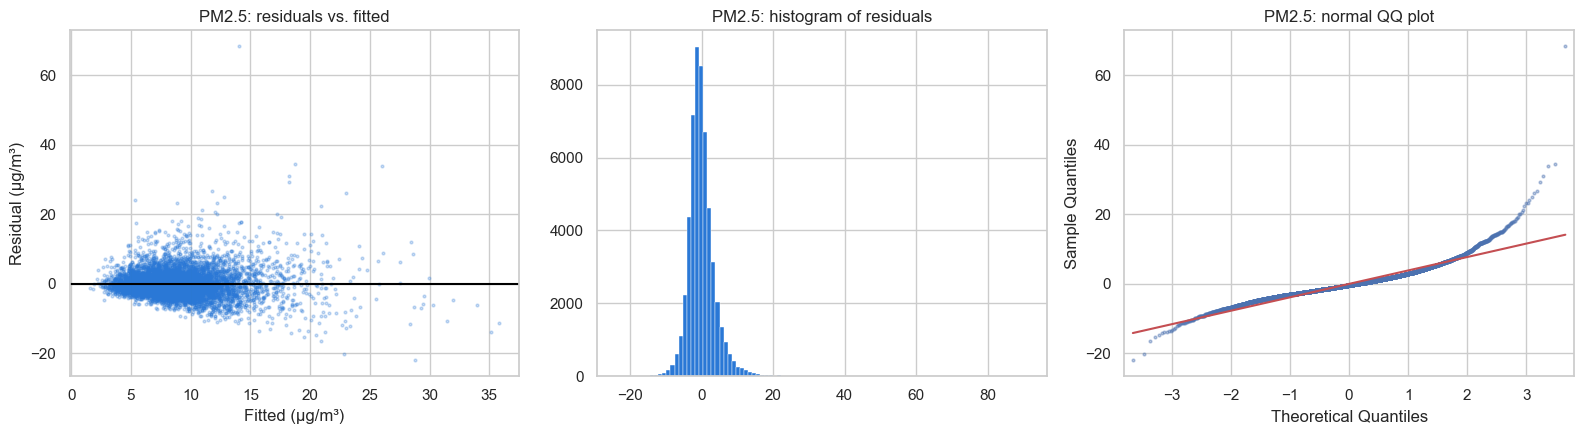

In [33]:
pm_resid = pm_final.resid
s = rng.choice(len(pm_resid), 8000, replace=False)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(pm_final.fittedvalues.iloc[s], pm_resid.iloc[s], s=4, alpha=0.25, color=ACTUAL_COLOR)
axes[0].axhline(0, color="black"); axes[0].set_title("PM2.5: residuals vs. fitted")
axes[0].set_xlabel("Fitted (µg/m³)"); axes[0].set_ylabel("Residual (µg/m³)")
axes[1].hist(pm_resid, bins=100, color=ACTUAL_COLOR, edgecolor="white", linewidth=0.3)
axes[1].set_title("PM2.5: histogram of residuals")
sm.qqplot(pm_resid.iloc[s], line="s", ax=axes[2], markersize=2, alpha=0.4)
axes[2].set_title("PM2.5: normal QQ plot")
plt.tight_layout()
plt.savefig(f"{FIGS}/pm25_residual_diagnostics.png", dpi=150)
plt.show()


**PM2.5 model:**
- **Backward elimination with BIC kept every candidate**, including weekend. PM2.5 is **0.24 µg/m³ lower on weekends** (p < 0.001), which fits less weekday traffic and industry.
- Same pattern as ozone: yesterday is the strongest predictor (0.609), 2 days ago is negative once yesterday is known (−0.140), and the weekly average adds a bit (0.114). Month is significant, with the highest values in **June–July** (+1.4 to +1.5 µg/m³ vs. January), the season of Saharan dust in Texas.
- R² = 0.433 and adjusted R² = 0.433; overall F = 2316, p ≈ 0.
- **VIFs are all below 4**, so there is no multicollinearity problem.
- **Assumptions:** Durbin-Watson = 2.00, so the errors are uncorrelated. **Normality clearly fails**: skew 2.05, kurtosis 25. The histogram has a long right tail and the QQ plot bends sharply upward. Residuals vs. fitted fans out, and Breusch-Pagan p ≈ 0. PM2.5 has sudden spikes (fireworks, smoke, dust) that a past-values model cannot foresee.


In [34]:
pm_pos = pm_train[(pm_train["pm25_ugm3"] > 0) & (pm_train[["pm25_yesterday", "pm25_2days_ago",
                  "pm25_3days_ago", "pm25_past7_avg"]] > 0).all(axis=1)].copy()
print("Site-days with a value <= 0 left out:", len(pm_train) - len(pm_pos))
_, pm_lam = stats.boxcox(pm_pos["pm25_ugm3"])
print(f"Box-Cox lambda for PM2.5: {pm_lam:.3f}")

Site-days with a value <= 0 left out: 177
Box-Cox lambda for PM2.5: 0.205



λ = 0.205, which is close to **λ = 0 → log(Y)** in the Box-Cox table (LR slide 70). As on LR slide 108, we log-transform the response and the past-PM2.5 predictors. The 177 site-days with a value ≤ 0 cannot be logged, so they are left out of this step.


In [35]:
pm_past = [c for c in pm_selected if c.startswith("pm25")]
pm_pos["log_pm25"] = np.log(pm_pos["pm25_ugm3"])
for c in pm_past:
    pm_pos[f"log_{c}"] = np.log(pm_pos[c])
log_rhs = [f"log_{c}" if c in pm_past else c for c in pm_selected]
pm_log = smf.ols("log_pm25 ~ " + " + ".join(log_rhs), data=pm_pos).fit()
pm_final_pos = fit_ols(pm_pos, "pm25_ugm3", pm_selected)

print(f"log model: R² = {pm_log.rsquared:.3f} (on the log scale)")
pd.concat({"original scale": assumption_tests(pm_final_pos, pm_pos)["statistic"],
           "log scale": assumption_tests(pm_log, pm_pos)["statistic"]}, axis=1).round(3)

log model: R² = 0.420 (on the log scale)


,original scale,log scale
Jarque-Bera (normality),1180257.301,27346.650
skew (normal = 0),2.061,-0.681
kurtosis (normal = 3),25.424,6.192
Breusch-Pagan (constant variance),1935.353,1041.826
"Durbin-Watson (independence, ideal ≈ 2)",2.002,2.005



**The log transformation helps a lot with the assumptions:**
- Jarque-Bera dropped from about 1,180,000 to 27,000. Skew went from 2.06 to −0.68 and kurtosis from 25.4 to 6.2, so the residuals are much closer to normal.
- Breusch-Pagan roughly halved (1,935 → 1,042), so the variance is more constant.


In [36]:
# predictions for 2024 with both models (the log model's predictions are converted back with exp)
pm_pred, pm_rep = prediction_report(pm_final, pm_test, "pm25_ugm3")

pm_test_pos = pm_test[(pm_test[["pm25_ugm3"] + pm_past] > 0).all(axis=1)].copy()
for c in pm_past:
    pm_test_pos[f"log_{c}"] = np.log(pm_test_pos[c])
log_pred = pm_log.get_prediction(pm_test_pos).summary_frame(alpha=0.05)
y = pm_test_pos["pm25_ugm3"].values
yhat = np.exp(log_pred["mean"].values)
low, highv = np.exp(log_pred["obs_ci_lower"].values), np.exp(log_pred["obs_ci_upper"].values)
pm_rep_log = {"R² (1 - SSE/SST)": 1 - ((y - yhat) ** 2).sum() / ((y - y.mean()) ** 2).sum(),
              "sqrt(MSE)": np.sqrt(((y - yhat) ** 2).mean()),
              "inside 95% prediction interval": ((y >= low) & (y <= highv)).mean()}

pm_table = pd.DataFrame({"original scale": {"R² on 2020–2023": pm_final.rsquared, **pm_rep},
                         "log scale (back-transformed)": {"R² on 2020–2023": np.nan, **pm_rep_log}}).T
print("PM2.5 standard deviation, 2020–2023:", round(pm_train["pm25_ugm3"].std(), 2),
      "| 2024:", round(pm_test["pm25_ugm3"].std(), 2))
pm_table.round(3)

PM2.5 standard deviation, 2020–2023: 5.23 | 2024: 7.04


,R² on 2020–2023,R² (1 - SSE/SST),sqrt(MSE),inside 95% prediction interval
original scale,0.433,0.504,4.958,0.926
log scale (back-transformed),NaN,0.443,5.244,0.948



**Predicting 2024 PM2.5:**
- **Original-scale model:** R² on 2024 = **0.504** and √MSE = 4.96 µg/m³. Only **92.6%** of 2024 values fall inside the 95% prediction interval, because the residuals are not normal, so the interval is wrong in the tails.
- **Log model (predictions converted back with exp):** **94.8%** of values fall inside the 95% interval, essentially the promised 95%. This is because its assumptions hold much better. But its R² is lower (0.443), because exp(predicted log) estimates the typical (median) level and undershoots the spikes.
- **Trade-off:** for a single best-guess number, use the original-scale model. For a trustworthy range, use the log model.

**Why is R² higher on 2024 (0.504) than on 2020–2023 (0.433)?** It is not overfitting, which would be the opposite. 2024 PM2.5 **varied more** (standard deviation 7.04 vs. 5.23 µg/m³). When high levels last several days, yesterday's value captures them, so a bigger share of the (larger) variation is explained.


In [37]:
summary = pd.DataFrame({
    "Ozone (ppb)": {"predictors kept by BIC": ", ".join(final_predictors),
                    "R² on 2020–2023": round(final.rsquared, 3),
                    "adjusted R² on 2020–2023": round(final.rsquared_adj, 3),
                    "R² on 2024 (new data)": round(rep_final["R² (1 - SSE/SST)"], 3),
                    "sqrt(MSE) on 2024": round(rep_final["sqrt(MSE)"], 2),
                    "2024 values inside 95% PI": round(rep_final["inside 95% prediction interval"], 3)},
    "PM2.5 (µg/m³)": {"predictors kept by BIC": ", ".join(pm_selected),
                      "R² on 2020–2023": round(pm_final.rsquared, 3),
                      "adjusted R² on 2020–2023": round(pm_final.rsquared_adj, 3),
                      "R² on 2024 (new data)": round(pm_rep["R² (1 - SSE/SST)"], 3),
                      "sqrt(MSE) on 2024": round(pm_rep["sqrt(MSE)"], 2),
                      "2024 values inside 95% PI": round(pm_rep["inside 95% prediction interval"], 3)},
})
summary.to_csv(f"{FIGS}/rq2_results.csv")
summary

,Ozone (ppb),PM2.5 (µg/m³)
predictors kept by BIC,"ozone_yesterday, ozone_2days_ago, ozone_past7_...","pm25_yesterday, pm25_2days_ago, pm25_3days_ago..."
R² on 2020–2023,0.533,0.433
adjusted R² on 2020–2023,0.533,0.433
R² on 2024 (new data),0.531,0.504
sqrt(MSE) on 2024,9.07,4.96
2024 values inside 95% PI,0.94,0.926



## Research Question 2: Summary

**Research question:** Can we use historical air quality data to predict pollutant concentrations?

**Answer: Yes, partly.** A multiple linear regression on a site's own recent values (plus season and location) explains about **half** of the day-to-day variation on a year it never saw: **R² = 0.53 for ozone** and **0.50 for PM2.5** in 2024. It cannot anticipate sudden high-pollution days.

**What we did (methods from the lecture slides only)**
1. **Variables (LR 11–13):** response = daily ozone MDA8 (ppb) at a site. Candidates = ozone 1, 2 and 3 days earlier, past 7-day average, yesterday's 24-h mean, latitude, longitude, month (categorical, 11 dummies), weekend. All are known before the predicted day.
2. **EDA (LR 31–33, 97–99):** histograms, correlation matrix. Yesterday has the strongest correlation (0.71), and the past-ozone predictors are correlated with each other.
3. **Simple linear regression (LR 34–35):** ozone = 11.12 + 0.713·yesterday, R² = 0.509.
4. **Multiple linear regression (LR 36–40):** all candidates, R² = 0.533. Overall F-test p ≈ 0. Weekend not significant. Marginal and conditional coefficients differ.
5. **Partial F-tests (LR 49–53):** month is significant as a group (F = 182, p ≈ 0).
6. **Multicollinearity (LR 85–88):** all VIFs < 10 (max 6.35).
7. **Variable selection (VS deck):** filter (variance threshold, F-values), forward and backward selection with AIC/BIC, Lasso with BIC. **BIC kept 7 predictors**, removing weekend and 3 days ago.
8. **Diagnostics (LR 57–68, 80–81, 89):** errors uncorrelated (DW = 2.00), linearity OK, residuals symmetric but heavy-tailed, variance not constant (larger on high days).
9. **Transformations (LR 69–70):** Box-Cox λ = 0.65 → √ozone fixed variance a bit but hurt normality, so not used. A squared term helped only marginally.
10. **Outliers (LR 72–76):** max Cook's D = 0.001, no influential points.
11. **Prediction (LR 54–56):** fitted on 2020–2023, predicted 2024 with 95% prediction intervals.
12. **PM2.5:** same steps. BIC kept all predictors. Residuals strongly non-normal → Box-Cox λ = 0.2 → log model gives correct interval coverage.

**Results**

| | Ozone (final model) | PM2.5 (final model) |
|---|---|---|
| Predictors kept by BIC | yesterday, 2 days ago, 7-day avg, yesterday's 24-h mean, lat, long, month | yesterday, 2 & 3 days ago, 7-day avg, lat, long, month, weekend |
| R² / adj. R², 2020–2023 | 0.533 / 0.533 | 0.433 / 0.433 |
| **R² on 2024 (new data)** | **0.531** | **0.504** |
| √MSE on 2024 | 9.07 ppb | 4.96 µg/m³ |
| 2024 values inside 95% PI | 94.0% | 92.6% (94.8% with log model) |

**Key interpretations**
- Yesterday's value dominates. Holding the other predictors fixed, 10 ppb more ozone yesterday → about 6.7 ppb more today.
- The coefficients on past values add up to less than 1, so predictions are pulled back toward normal levels.
- Season matters even after accounting for past values: spring and September ozone run 3–4 ppb above January.
- Training and 2024 R² are about the same for ozone, so the model is not overfitting.

**Limitations**
- **High-pollution days are missed.** On 2024 ozone days ≥ 70 ppb: actual mean 77.0 vs. predicted 55.4 ppb, only 14 of 560 predicted ≥ 70, and only 36% inside the prediction interval.
- **Non-constant variance**, so prediction intervals are too narrow on high days. PM2.5 residuals are strongly non-normal on the original scale.
- **No weather data** (temperature, sunlight, wind), the main drivers of ozone and PM2.5 episodes.
- **One pooled model for all sites.** Tested on one year (2024) only.
- With ~93,000 rows almost every p-value is tiny, so we relied on BIC/adjusted R² for model choice, not only on p-values.

### 60–75 second presentation script

> "Our second research question was whether historical air quality data can predict pollutant concentrations. We used multiple linear regression to predict each Texas site's daily ozone. Our candidate predictors were the site's values from the previous three days, its past-week average, yesterday's 24-hour average, the site's location, the month as a categorical variable, and a weekend indicator.
>
> We checked correlations and VIFs, then used forward and backward selection with BIC. BIC kept seven predictors and dropped weekend and three-days-ago. The month dummies were significant together in a partial F-test, so season matters. Durbin-Watson was 2, so the errors are uncorrelated. The residuals were symmetric but had heavier tails than normal, and the error variance grows on high-ozone days.
>
> We fitted on 2020 to 2023 and predicted 2024 as new data. The model explained 53 percent of the variation, the same as in training, so it isn't overfitting, and 94 percent of 2024 values fell inside the 95 percent prediction intervals. PM2.5 gave the same picture, with an R-squared of 0.50.
>
> So historical data predicts typical days well, but it misses high-pollution days. On days above the 70 ppb ozone standard, we predicted about 55 ppb on average. Those spikes are driven by weather, which isn't in our data."

### Figures (saved in `EDA_Results/RQ2_regression/`)
- `ozone_eda_histograms.png`, `ozone_correlation_heatmap.png`: EDA
- `ozone_lasso_path.png`: Lasso coefficient path
- `ozone_residual_diagnostics.png`, `ozone_residuals_vs_predictors.png`: assumption checks
- `ozone_cooks_distance.png`: outliers
- `ozone_actual_vs_predicted_frisco_2024.png`, `ozone_actual_vs_predicted_scatter.png`: 2024 predictions
- `pm25_residual_diagnostics.png`: PM2.5 assumption checks
- `rq2_results.csv`: summary table
